In [1]:
%load_ext autoreload
%autoreload 2

import sys, copy, os
from pathlib import Path
import numpy as np

root_dir = Path.cwd().parent
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))
from matplotlib import pyplot as plt

# from run_detection import run_detection
import caiman
from caiman.source_extraction import cnmf as cnmf
from caiman.motion_correction import MotionCorrect

from neuron_detection import motion_correct, neuron_detection, CaImAn_params, make_tif_stack
# from image_processing.motion_correct import motion_correct, plot_results_motion_correction
# from image_processing.neuron_detection import neuron_detection
# from utils.parameters import CaImAn as CaImAn_params, params_motion

os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

In [2]:
prefix = "results_CaImAn"
suffix = "_test_mc"
save_type = "hdf5"  # "mat" or "hdf5"
n_processes = 12

# tmp_dir = Path("/home/wollex/caiman_data/temp")
# session_path = Path("../../../../data/Subhodeep/ID45/20230912/")
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/845ad/Session01"
)

In [4]:
fname = [file for file in session_path.iterdir() if file.suffix == ".tif"][0]
print("Processing file:", fname)
# path_to_motion_correct = [file for file in tmp_dir.iterdir() if file.suffix == ".mmap"][
#     0
# ]

resultFile_name = f"{prefix}_{Path(fname).stem}{suffix}"
result_path = session_path / f"{resultFile_name}.{save_type}"
use_parallel = n_processes is not None and n_processes > 1

print(result_path)

Processing file: /home/wollex/Data/ScienceData/turnover_analysis/KotaroData/845ad/Session01/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am.tif
/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/845ad/Session01/results_CaImAn_ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am_test_mc.hdf5


In [7]:
root_dir = Path.cwd().parents[2]
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))
root_dir

PosixPath('/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis')

In [10]:
from utils.display_videos import display_videos

display_videos([fname], f=15.0)

(8989, 512, 512) <class 'numpy.float32'>
dims=(8989, 512, 512)
dims=(8989, 512, 512)


TypeError: 'tuple' object is not callable

In [4]:
from scipy.ndimage import gaussian_filter1d
from tifffile import imread, imwrite

# Load the TIF file
print(f"Loading data from {fname}...")
data = imread(fname)
print(f"Data shape: {data.shape}")
data = data[:2000, ...]
data = data.astype(np.float32)

# Determine time axis (usually first axis in CaImAn convention)
time_axis = 0 if data.shape[0] > data.shape[-1] else -1
print(f"Time axis: {time_axis}")

# Apply temporal Gaussian filter
# sigma_temporal = 1.0  # adjust this value for more/less smoothing
# print(f"Applying temporal Gaussian filter (sigma={sigma_temporal})...")
# data_filtered = gaussian_filter1d(data, sigma=sigma_temporal, axis=time_axis)

# # Optional: Apply spatial Gaussian filter (uncomment if needed)
# # sigma_spatial = 0.5
# # for spatial_axis in [ax for ax in range(data.ndim) if ax != time_axis]:
# #     data_filtered = gaussian_filter1d(data_filtered, sigma=sigma_spatial, axis=spatial_axis)

# # Create output filename with "filtered" suffix
# output_fname = fname.parent / f"{fname.stem}_filtered{fname.suffix}"
# print(f"Saving filtered data to {output_fname}...")
# imwrite(output_fname, data_filtered.astype(data.dtype))

# print("Filtering complete!")

Loading data from /home/wollex/Data/ScienceData/turnover_analysis/845ad/Session01/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am.tif...
Data shape: (8989, 512, 512)
Time axis: 0


In [ ]:
from scipy.ndimage import gaussian_filter1d, gaussian_filter

T_cut = 1000
# fname_filtered = output_fname
sigma_temporal = 2.0
data_filtered = gaussian_filter(data[:T_cut, ...], sigma=(sigma_temporal, 1.0, 1.0))
fname_short_filtered = fname.parent / f"{fname.stem}_short_filtered{fname.suffix}"
print(f"Saving filtered data to {fname_short_filtered}...")
imwrite(fname_short_filtered, data_filtered.astype(data.dtype))

fname_short = fname.parent / f"{fname.stem}_short{fname.suffix}"
# print(f"Saving original data to {fname_short}...")
# imwrite(fname_short, data[:T_cut, ...].astype(data.dtype))

Saving filtered data to /home/wollex/Data/ScienceData/turnover_analysis/845ad/Session01/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am_short_filtered.tif...


In [19]:
from scipy.ndimage import median_filter

data_median = median_filter(data[:T_cut], size=(5, 1, 1))
fname_short_median = fname.parent / f"{fname.stem}_short_median1d{fname.suffix}"
print(f"Saving filtered data to {fname_short_median}...")
imwrite(fname_short_median, data_median.astype(data.dtype))

Saving filtered data to /home/wollex/Data/ScienceData/turnover_analysis/845ad/Session01/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am_short_median1d.tif...


In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


Motion correction with params: {'fr': 15.0, 'decay_time': 1.5, 'dxy': 0.9647998794000152, 'rf': 48, 'stride': 8, 'border_pix': 0, 'nb': 2, 'gSig': [10, 10], 'gSiz': (21, 21), 'min_SNR': 2.5, 'SNR_lowest': 1.0, 'rval_thr': 0.8, 'rval_lowest': -1, 'min_cnn_thr': 0.9, 'cnn_lowest': 0.1, 'use_cnn': True, 'motion_correct': False, 'epochs': 1, 'normalize': True, 'init_batch': 1000, 'init_method': 'cnmf', 'dist_shape_update': True, 'update_freq': 1000, 'use_dense': False, 'merge_thr': 0.65, 'max_shifts': (12, 12), 'strides': (96, 96), 'overlaps': (24, 24), 'max_deviation_rigid': 6, 'pw_rigid': True, 'show_movie': False, 'save_online_movie': False, 'niter_rig': 1, 'upsample_factor_grid': 4, 'shifts_opencv': True, 'gSig_filt': (4, 4)}
	Now running motion correction @t = Thu Jan 29 08:52:00 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  3.14it/s]


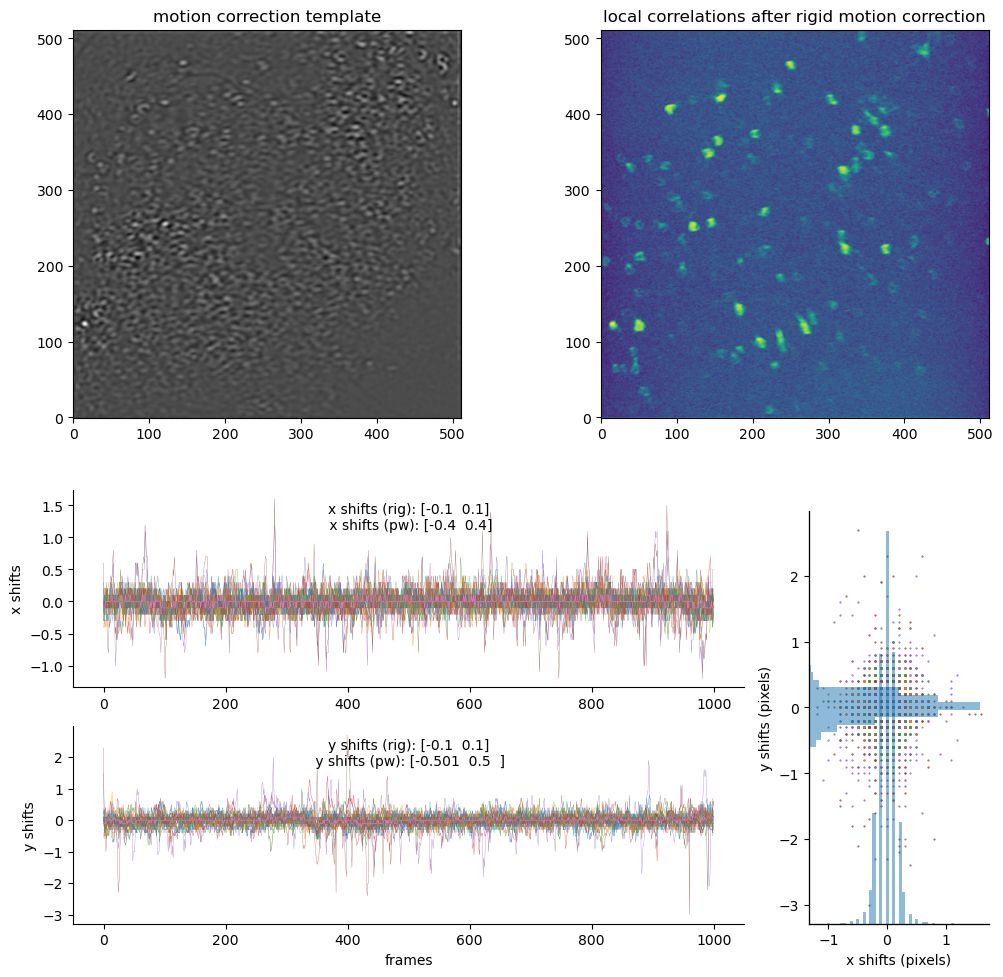

	Motion correction done @t = Thu Jan 29 08:52:43 2026, (time passed: 43.16150689125061)


In [24]:
# params = copy.deepcopy(params_motion)
params = copy.deepcopy(CaImAn_params)
params["fr"] = 15.0
params["pw_rigid"] = True
params["niter_rig"] = 1
params["upsample_factor_grid"] = 4
params["shifts_opencv"] = True
params["gSig_filt"] = (4, 4)

# params.update(additional_params)
print("Motion correction with params:", params)

if "dview" in locals():  # 'locals' contains list of current local variables
    caiman.stop_server(dview=dview)
path_to_motion_correct = motion_correct(
    fname_short_median,
    params=params,
    n_processes=6,
    path_destination=session_path,
    plot=True,
)

In [6]:
root_dir = Path.cwd().parents[2]
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))

In [16]:
sys.path

['/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis',
 '/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics',
 '/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman',
 '/home/wollex/miniforge3/envs/caiman/lib/python311.zip',
 '/home/wollex/miniforge3/envs/caiman/lib/python3.11',
 '/home/wollex/miniforge3/envs/caiman/lib/python3.11/lib-dynload',
 '',
 '/home/wollex/miniforge3/envs/caiman/lib/python3.11/site-packages',
 '/home/wollex/miniforge3/envs/caiman/lib/python3.11/site-packages/setuptools/_vendor',
 '/tmp/tmpzd3r81kk']

In [ ]:
from scipy.ndimage import gaussian_filter

sigma_temporal = 1.0
data_filtered = gaussian_filter(data[:T_cut], sigma=(sigma_temporal, 1, 1))

In [24]:
fname_short_filtered3d = fname.parent / f"{fname.stem}_short_filtered3d{fname.suffix}"
print(f"Saving filtered data to {fname_short_filtered3d}...")
imwrite(fname_short_filtered3d, data_filtered[:T_cut, ...].astype(data.dtype))

Saving filtered data to /home/wollex/Data/ScienceData/turnover_analysis/845ad/Session01/ad_homo#845_hp_16x1.5x_134um_90v91v_57p_res_lave2_am_short_filtered3d.tif...


In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Wed Jan 28 15:45:59 2026


100%|██████████| 1/1 [00:01<00:00,  1.53s/it]


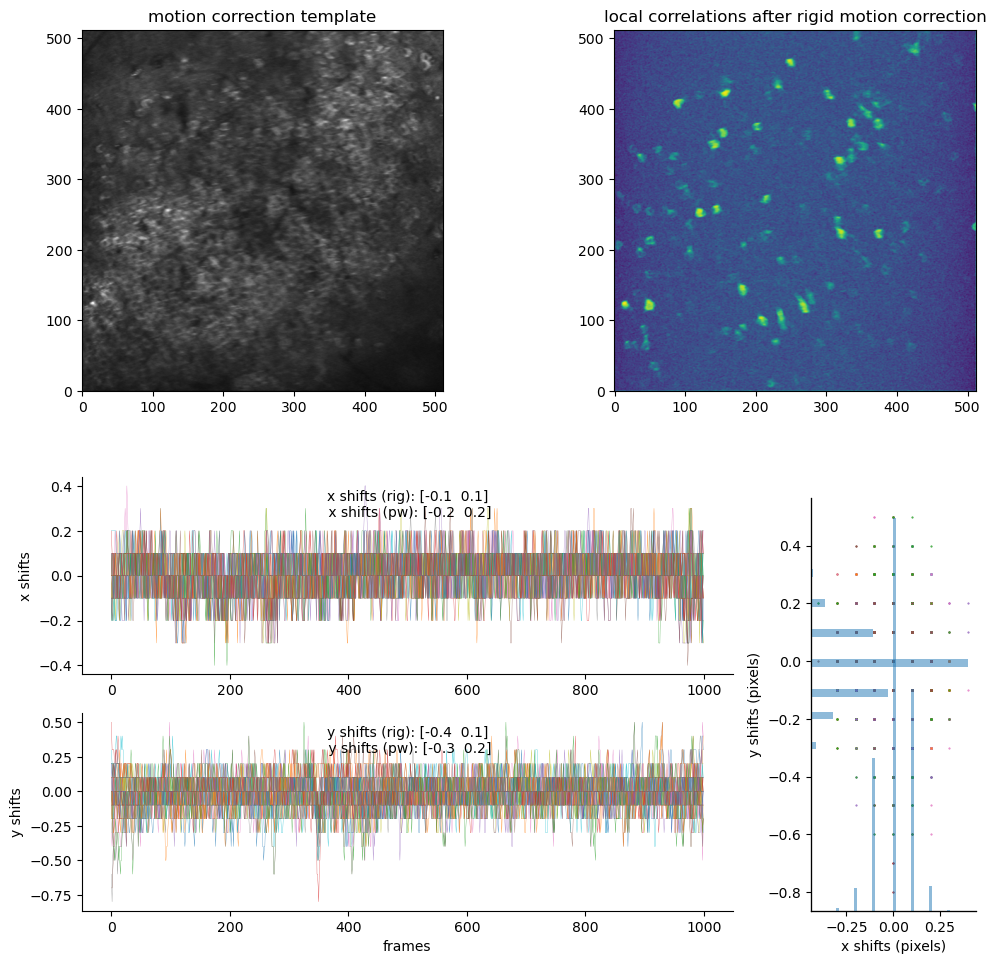

	Motion correction done @t = Wed Jan 28 15:46:41 2026, (time passed: 42.19715738296509)


In [31]:
path_to_motion_correct = motion_correct(
    fname_short_median,
    params=params,
    n_processes=6,
    path_destination=session_path,
    plot=True,
)

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Wed Jan 28 15:20:15 2026


100%|██████████| 1/1 [00:00<00:00,  3.17it/s]


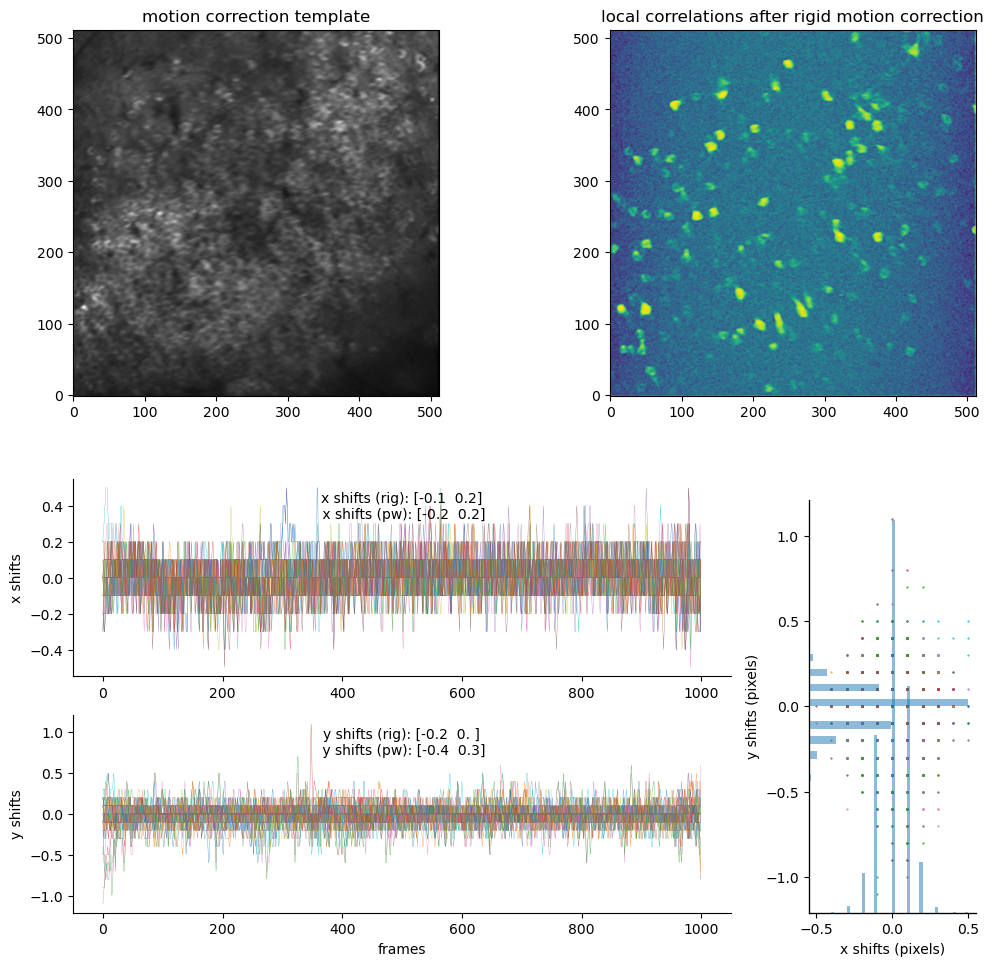

	Motion correction done @t = Wed Jan 28 15:20:56 2026, (time passed: 41.3801634311676)


In [25]:
path_to_motion_correct = motion_correct(
    fname_short_filtered3d,
    params=params,
    n_processes=6,
    path_destination=session_path,
    plot=True,
)

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Wed Jan 28 15:16:46 2026


100%|██████████| 1/1 [00:00<00:00,  3.11it/s]


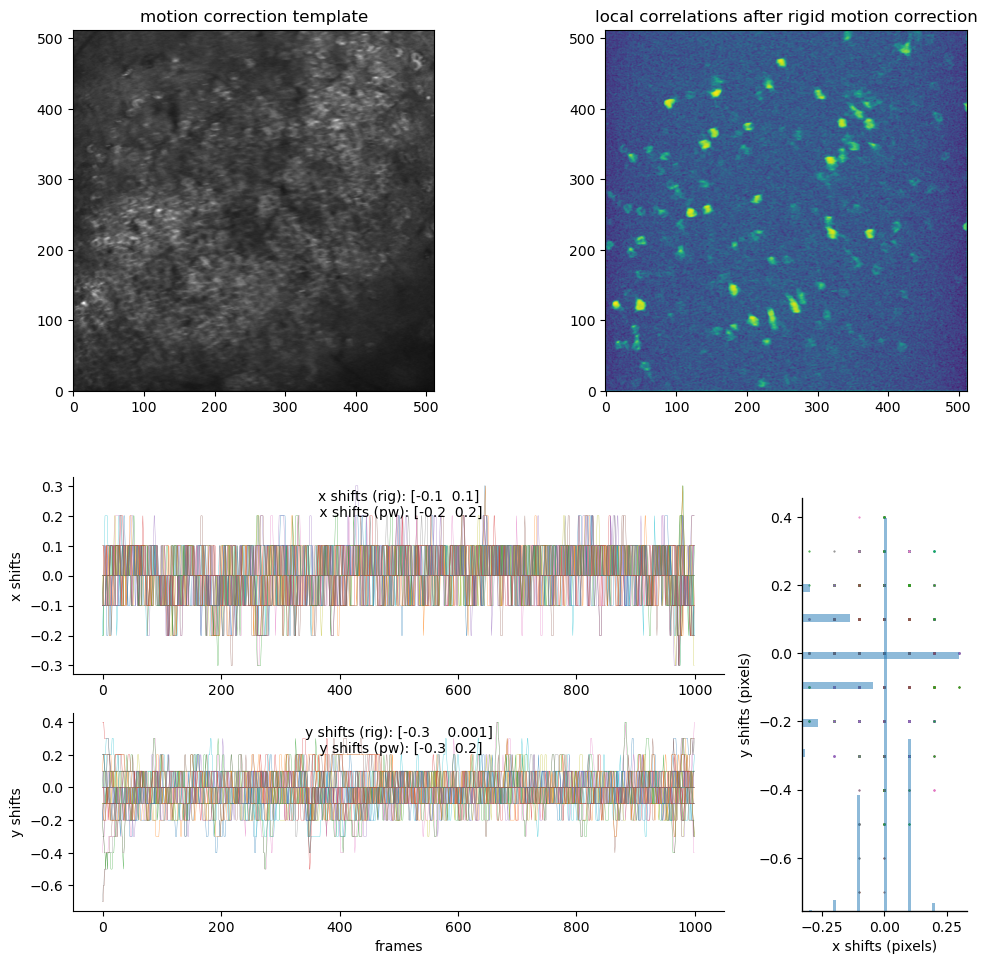

	Motion correction done @t = Wed Jan 28 15:17:27 2026, (time passed: 40.745914697647095)


In [22]:
path_to_motion_correct = motion_correct(
    fname_short_filtered2,
    params=params,
    n_processes=6,
    path_destination=session_path,
    plot=True,
)

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Wed Jan 28 15:13:50 2026


100%|██████████| 1/1 [00:00<00:00,  2.44it/s]


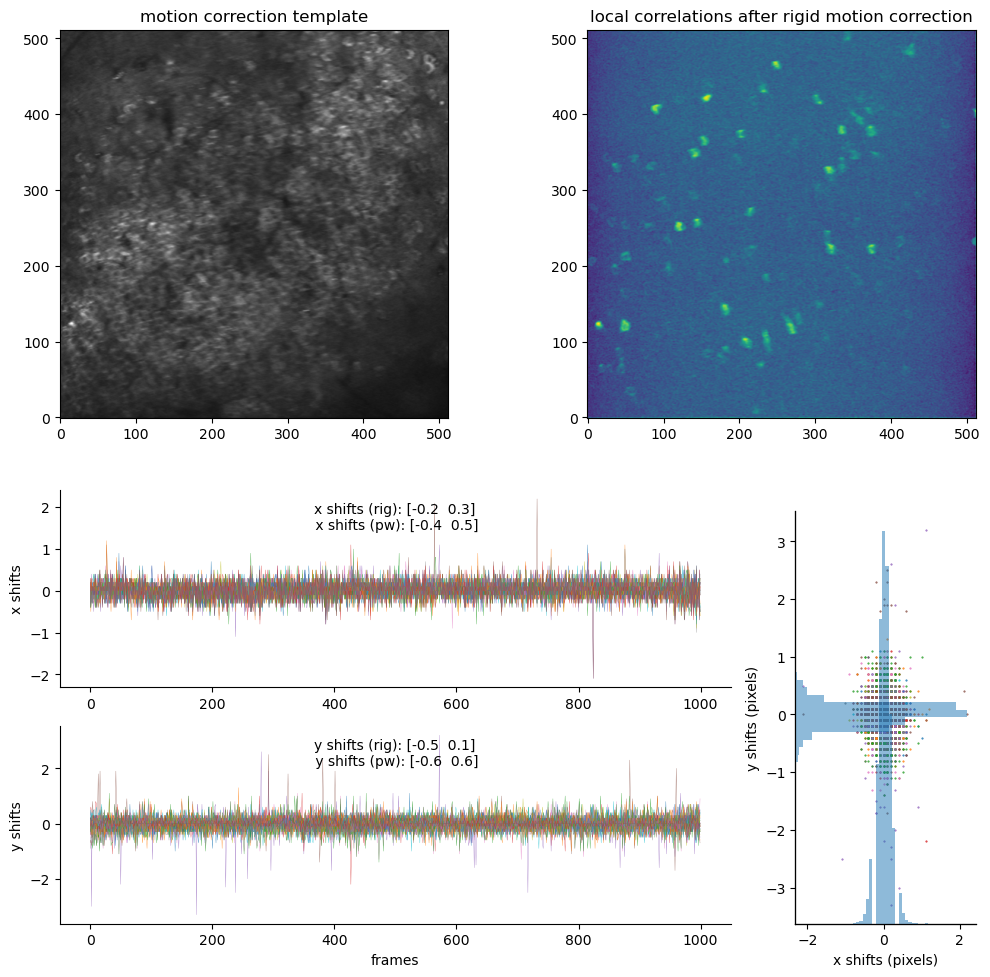

	Motion correction done @t = Wed Jan 28 15:14:33 2026, (time passed: 43.45923662185669)


In [19]:
path_to_motion_correct = motion_correct(
    fname_short,
    params=params,
    n_processes=6,
    path_destination=session_path,
    plot=True,
)